In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf

In [7]:
sleep_df = pd.read_csv("Sleep_health_and_lifestyle_dataset.csv", keep_default_na=False)
student_train = pd.read_csv("train.csv")
student_test = pd.read_csv("test.csv")

print("Sleep       :", sleep_df.shape)
print("Student train:", student_train.shape)
print("Student test :", student_test.shape)

Sleep       : (374, 13)
Student train: (16000, 19)
Student test : (4000, 18)


In [9]:
# Bandingkan: baca dengan cara default pandas vs cara yang benar
sleep_default = pd.read_csv("Sleep_health_and_lifestyle_dataset.csv")

print("Cara default, jumlah NaN di Sleep Disorder:",
      sleep_default["Sleep Disorder"].isna().sum())
print()
print("Cara benar (keep_default_na=False):")
print(sleep_df["Sleep Disorder"].value_counts())

Cara default, jumlah NaN di Sleep Disorder: 219

Cara benar (keep_default_na=False):
Sleep Disorder
None           219
Sleep Apnea     78
Insomnia        77
Name: count, dtype: int64


In [10]:
print("Total baris:", len(sleep_df))
print("Duplikat (tanpa Person ID):",
      sleep_df.drop(columns="Person ID").duplicated().sum())
print()
print("Jumlah kosong per kolom:")
print(sleep_df.isna().sum())

Total baris: 374
Duplikat (tanpa Person ID): 242

Jumlah kosong per kolom:
Person ID                  0
Gender                     0
Age                        0
Occupation                 0
Sleep Duration             0
Quality of Sleep           0
Physical Activity Level    0
Stress Level               0
BMI Category               0
Blood Pressure             0
Heart Rate                 0
Daily Steps                0
Sleep Disorder             0
dtype: int64


In [11]:
fitur = ["Sleep Duration", "Quality of Sleep",
         "Physical Activity Level", "Stress Level"]
sleep_df[fitur].describe()

,Sleep Duration,Quality of Sleep,Physical Activity Level,Stress Level
count,374.000000,374.000000,374.000000,374.000000
mean,7.132086,7.312834,59.171123,5.385027
std,0.795657,1.196956,20.830804,1.774526
min,5.800000,4.000000,30.000000,3.000000
25%,6.400000,6.000000,45.000000,4.000000
50%,7.200000,7.000000,60.000000,5.000000
75%,7.800000,8.000000,75.000000,7.000000
max,8.500000,9.000000,90.000000,8.000000


In [12]:
sleep_df.groupby("Sleep Disorder")[fitur].mean().round(2)

,Sleep Duration,Quality of Sleep,Physical Activity Level,Stress Level
Sleep Disorder,,,,
Insomnia,6.59,6.53,46.82,5.87
None,7.36,7.63,57.95,5.11
Sleep Apnea,7.03,7.21,74.79,5.67


In [13]:
fitur = ["Sleep Duration", "Quality of Sleep",
         "Physical Activity Level", "Stress Level"]

unik = sleep_df[fitur + ["Sleep Disorder"]].drop_duplicates()

print("Baris asli       :", len(sleep_df))
print("Baris unik       :", len(unik))
print()
print("Sebelum dihapus duplikat:")
print(sleep_df["Sleep Disorder"].value_counts())
print()
print("Sesudah dihapus duplikat:")
print(unik["Sleep Disorder"].value_counts())

Baris asli       : 374
Baris unik       : 92

Sebelum dihapus duplikat:
Sleep Disorder
None           219
Sleep Apnea     78
Insomnia        77
Name: count, dtype: int64

Sesudah dihapus duplikat:
Sleep Disorder
None           47
Insomnia       23
Sleep Apnea    22
Name: count, dtype: int64


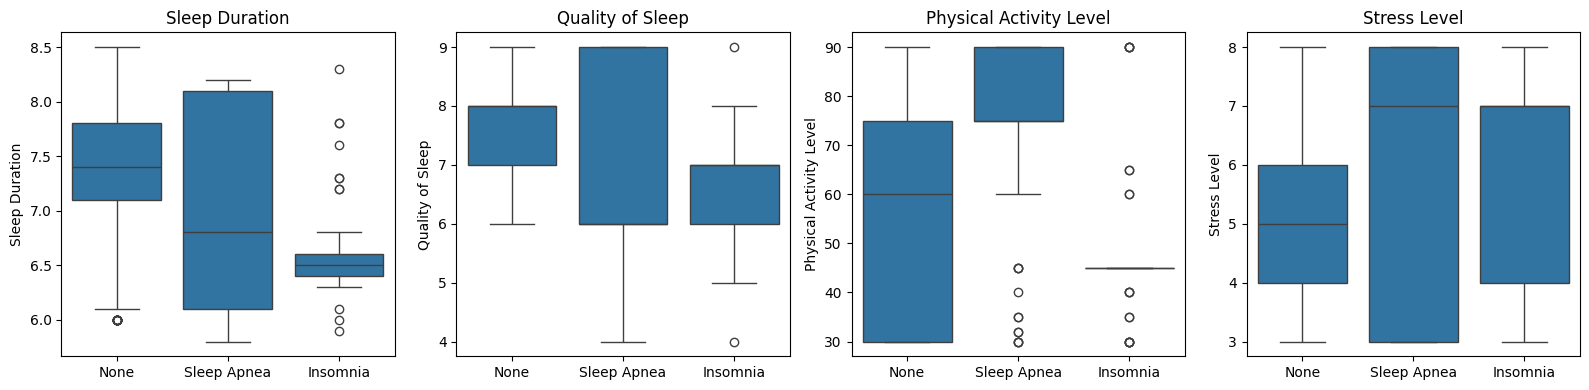

In [14]:
import matplotlib.pyplot as plt
import seaborn as sns

fig, axes = plt.subplots(1, 4, figsize=(16, 4))
for ax, kolom in zip(axes, fitur):
    sns.boxplot(data=sleep_df, x="Sleep Disorder", y=kolom, ax=ax)
    ax.set_title(kolom)
    ax.set_xlabel("")
plt.tight_layout()
plt.show()

In [15]:
print(student_train.shape)
print("Jumlah kosong total:", student_train.isna().sum().sum())
print("id duplikat        :", student_train["id"].duplicated().sum())
print("student_id duplikat:", student_train["student_id"].duplicated().sum())
print()
print(student_train["gender"].value_counts())
student_train.describe().T.round(2)

(16000, 19)
Jumlah kosong total: 0
id duplikat        : 0
student_id duplikat: 0

gender
Male      7704
Female    7683
Other      613
Name: count, dtype: int64


,count,mean,std,min,25%,50%,75%,max
id,16000.0,10006.51,5790.79,1.0,4993.75,10020.50,15029.25,19999.00
student_id,16000.0,10007.51,5790.79,2.0,4994.75,10021.50,15030.25,20000.00
age,16000.0,23.02,3.75,17.0,20.00,23.00,26.00,29.00
study_hours_per_day,16000.0,5.25,2.74,0.5,2.89,5.25,7.63,10.00
sleep_hours,16000.0,6.52,2.03,3.0,4.76,6.52,8.32,10.00
phone_usage_hours,16000.0,6.26,3.31,0.5,3.39,6.23,9.10,12.00
social_media_hours,16000.0,4.00,2.31,0.0,2.00,3.99,5.97,8.00
youtube_hours,16000.0,2.99,1.73,0.0,1.48,2.97,4.48,6.00
gaming_hours,16000.0,2.98,1.73,0.0,1.48,2.95,4.49,6.00
breaks_per_day,16000.0,7.54,4.02,1.0,4.00,8.00,11.00,14.00


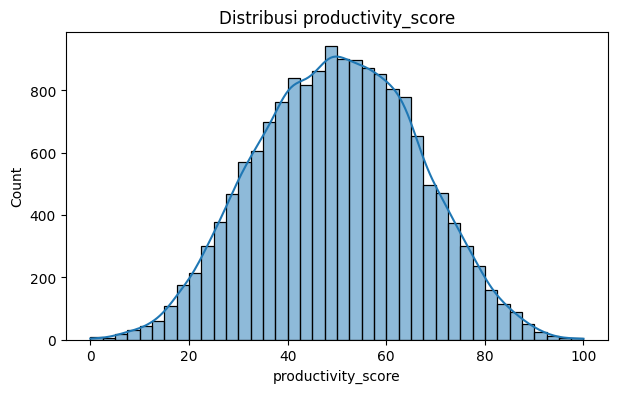

,productivity_score
count,16000.00
mean,50.15
std,16.10
min,0.00
25%,38.66
50%,50.22
75%,61.84
max,100.00


In [16]:
plt.figure(figsize=(7, 4))
sns.histplot(student_train["productivity_score"], bins=40, kde=True)
plt.title("Distribusi productivity_score")
plt.show()

student_train["productivity_score"].describe().round(2)

phone_usage_hours       -0.327
stress_level            -0.196
breaks_per_day          -0.007
age                     -0.004
social_media_hours       0.000
final_grade              0.000
gaming_hours             0.001
exercise_minutes         0.002
youtube_hours            0.002
assignments_completed    0.005
student_id               0.011
id                       0.011
coffee_intake_mg         0.020
attendance_percentage    0.175
sleep_hours              0.339
focus_score              0.415
study_hours_per_day      0.732
Name: productivity_score, dtype: float64


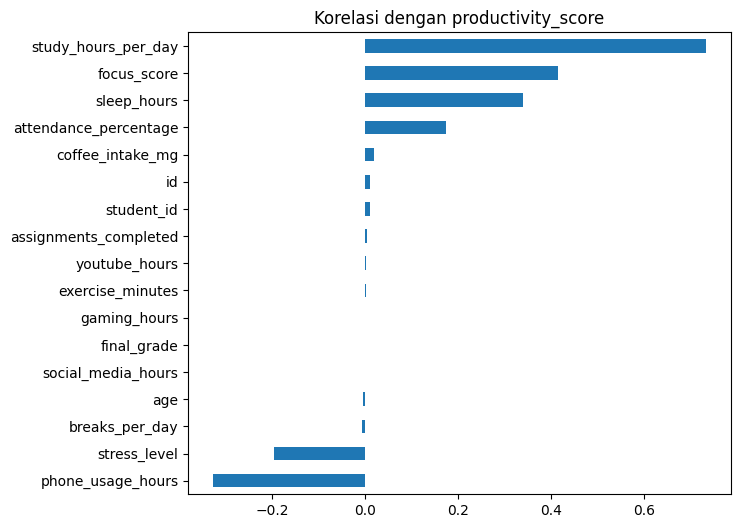

In [17]:
korelasi = (student_train.corr(numeric_only=True)["productivity_score"]
            .drop("productivity_score")
            .sort_values())
print(korelasi.round(3))

korelasi.plot(kind="barh", figsize=(7, 6))
plt.title("Korelasi dengan productivity_score")
plt.show()

In [18]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_absolute_error

target = student_train["productivity_score"]

kumpulan_fitur = {
    "B: 5 fitur yang bisa dipetakan": ["sleep_hours", "stress_level", "phone_usage_hours",
                                       "exercise_minutes", "coffee_intake_mg"],
    "C: B + study_hours": ["sleep_hours", "stress_level", "phone_usage_hours",
                           "exercise_minutes", "coffee_intake_mg", "study_hours_per_day"],
}

for nama, kolom in kumpulan_fitur.items():
    X_latih, X_uji, y_latih, y_uji = train_test_split(
        student_train[kolom], target, test_size=0.2, random_state=42)
    model = LinearRegression().fit(X_latih, y_latih)
    prediksi = model.predict(X_uji)
    print(nama)
    print("  R2 :", round(r2_score(y_uji, prediksi), 3))
    print("  MAE:", round(mean_absolute_error(y_uji, prediksi), 2))

B: 5 fitur yang bisa dipetakan
  R2 : 0.254
  MAE: 11.68
C: B + study_hours
  R2 : 0.807
  MAE: 5.99
